## assignment 6: variational autoencoder (VAE)

## Overview:
---
### This time, we use the same example from assignment 5, *yet again*, but we now have to implement $\mu$ (mu/mean) and $\ln(\sigma^2)$ (logvar/log variance), as well as the reparameterization trick and ultimately create a VAE.

### Pros (in theory):
- Better representational capacity
- Smoother, gaussian latent space for sampling

In [1]:
#same dataset, again...
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

# 1. Setup random seed
torch.manual_seed(42)

# 2. Download and prepare the professional MNIST dataset
# This automatically scales the pixel values between 0.0 and 1.0!
transform = transforms.Compose([transforms.ToTensor()])

train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# 3. Create the DataLoader factories (Chops data into mini-batches of 64 images)
train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_dataset, batch_size=64, shuffle=False)


In [2]:
import torch
import torch.nn as nn

#we will be modifying the Encoder and other layers from last time...
class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.l1 = nn.Sequential(
            nn.Linear(784, 64), # compress to hidden dim
            nn.ReLU(), # activate to "spline" it (it, as in the multiple Wx + b's)
        )
        #instead of the old nn.Linear(64, 2) in l1/the sequential...
        self.fc_mu = nn.Linear(64, 2)
        self.fc_logvar = nn.Linear(64, 2)
        #BOOM! two parallel layers that will compute the mean and the log-variance!
    def forward(self, x):
        features = self.l1(x) #get raw features first
        mu = self.fc_mu(features)
        logvar = self.fc_logvar(features)
        return mu, logvar

class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.l1 = nn.Sequential(
            nn.Linear(2, 64), #decompress/project upwards to 64
            nn.ReLU(), #re-active/re-spline
            nn.Linear(64, 784), #back to 784-pixel-space
            #nn.Sigmoid(), #ensure outputs within range [0,1] where 0 is black pixels and 1 is white pixels
            #removed sigmoid because we will be using BCEWithLogitsLoss which combines sigmoid and binary cross-entropy in a numerically stable way
        )
    def forward(self, z):
        return self.l1(z)

class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = Encoder()
        self.decoder = Decoder()
    def reparameterize(self, mu, logvar):
        # 1. logvar must be converted to std
        std = torch.exp(0.5 * logvar) #simply put, halves each element and raises e to each result for each element
        eps = torch.randn_like(mu) #seemingly counterintuitive at first; sample a random/gaussian vector same size as mu
        z = mu + eps * std #REPARAMETERIZAITON TRICK: add the mean to the random vector times std
        #this is precisely what makes the "randomness" actually differentiable allowing for backpropagation.
        return z
    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = self.reparameterize(mu, logvar)
        y_hat = self.decoder(z)
        return y_hat, mu, logvar

model = VAE()

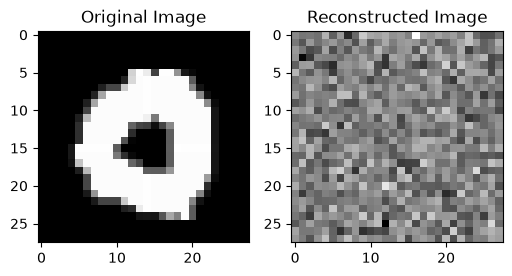

Epoch 1 | Average Loss: 0.6252


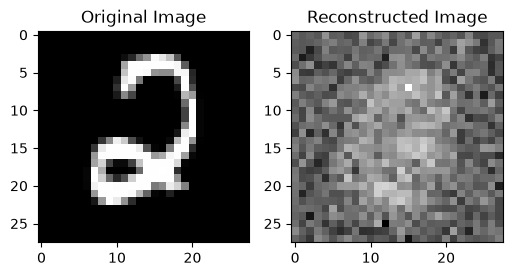

Epoch 2 | Average Loss: 0.4279


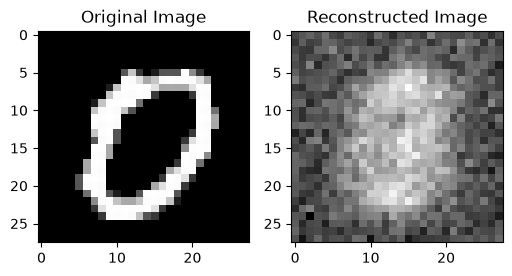

Epoch 3 | Average Loss: 0.3121


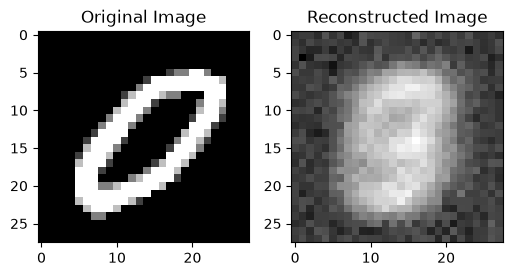

Epoch 4 | Average Loss: 0.2836


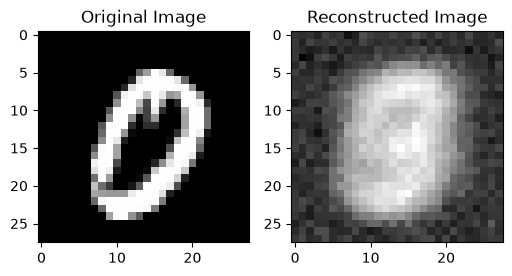

Epoch 5 | Average Loss: 0.2749


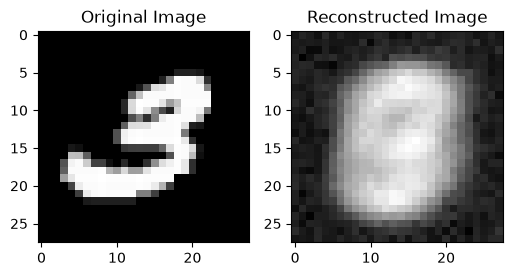

Epoch 6 | Average Loss: 0.2710


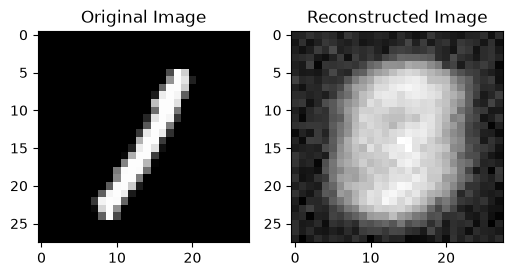

Epoch 7 | Average Loss: 0.2689


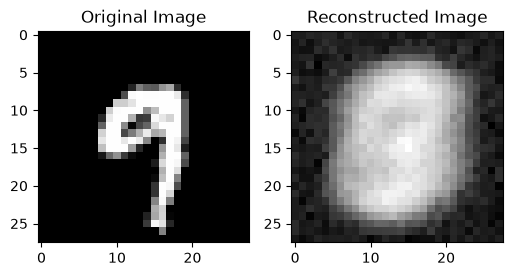

Epoch 8 | Average Loss: 0.2676


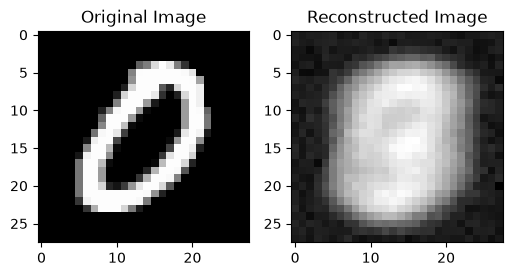

Epoch 9 | Average Loss: 0.2667


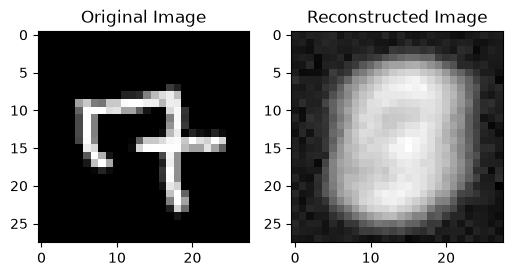

Epoch 10 | Average Loss: 0.2661


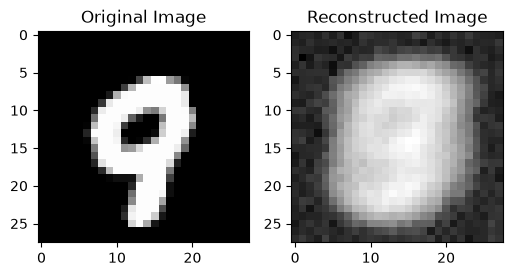

Epoch 11 | Average Loss: 0.2656


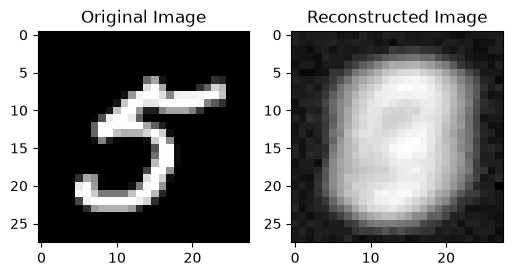

Epoch 12 | Average Loss: 0.2653


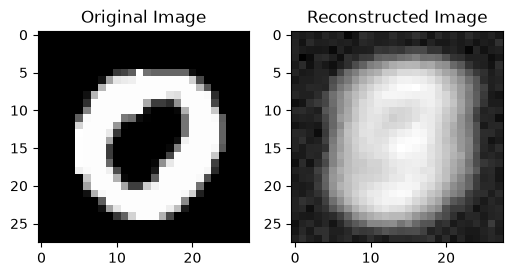

Epoch 13 | Average Loss: 0.2650


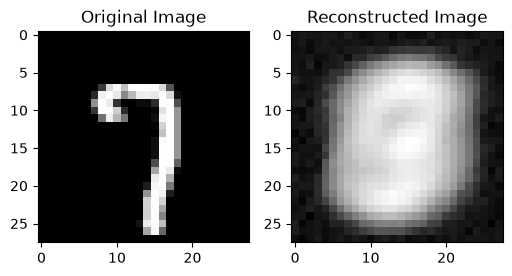

Epoch 14 | Average Loss: 0.2648


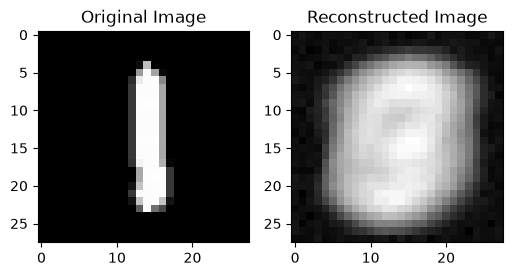

KeyboardInterrupt: 

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision.transforms import v2
import matplotlib.pyplot as plt


optimizer = optim.SGD(lr=1e-1, params=model.parameters())
#criterion = nn.MSELoss() 
#no more simplistic-style naive MSE loss

def train(epochs=100):
    for epoch in range(epochs):
        total_loss = 0
        for batch_idx, (inputs, targets) in enumerate(train_loader):
            optimizer.zero_grad()
            flattened = inputs.view(inputs.size(0),-1)
            #difference #1: notice that we will now have 3 terms fighting for the loss
            y_hat, mu, logvar = model(flattened)
            recon_loss = F.binary_cross_entropy_with_logits(y_hat, flattened, reduction="mean")
            KL_loss = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())#KL Divergence loss, or more formally, Kullback-Leibler Divergence loss.
            #note: i am using the mean for the KL loss instead of the regular sum, as it is more stable and averages across any batch size
            loss = recon_loss + KL_loss
            loss.backward()
            #now that we are dealing with a potentially unstable VAE, we will need to clip the gradients to avoid exploding gradients
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0) 
            optimizer.step()
            total_loss += loss.item()
            if batch_idx == 0: #every 1st sub-batch/batch
                model.eval() #eval mode real quick
                with torch.no_grad():
                    orig_img = flattened.reshape(64,28,28).numpy()[0]
                    reconstructed = y_hat.reshape(64,28,28).numpy()[0]
                    fig, axes = plt.subplots(1,2,figsize=(6,3))
                    axes[0].imshow(orig_img,cmap="gray")
                    axes[0].set_title("Original Image")
                    axes[1].imshow(reconstructed,cmap="gray")
                    axes[1].set_title("Reconstructed Image")
                    plt.show()
                    plt.close(fig)
                model.train() #back to training
        avg_loss = total_loss / len(train_loader)
        print(f"Epoch {epoch+1} | Average Loss: {avg_loss:.4f}")

train()
        

## quick writeup:

### as you may have noticed, the output has stalled and seems to be a blurry average. why is that? the truth really is; nothing inherently went *wrong* with our model, per se, but now with the additional KL term fighting for latent "smoothness" against pure reconstruction loss, the safest way to decrease the loss becames to output a smooth "average" of most of the digits! also keep in mind that our model has an absolutely brutal bottleneck of just **two** neurons. if you were to upgrade the size of the bottleneck, it would likely be able to learn and generalize better with no problem, as backed by the Universal Approximation Theory (UAT).